# Carbonate reef terraces: results

Coral reef terraces built by Quaternary sea-level changes (Pastier et al., 2019),
with goSPL's carbonate module, wave energy and coastal erosion. The runs are
described in `README.md` and in the header of each `input-*.yml`; run
`python scripts/make_inputs.py` and `./run_all.sh` first.

In [1]:
%matplotlib inline
import sys
import matplotlib.pyplot as plt
sys.path.insert(0, 'scripts')
import terraces as T

## The forcing

Relative sea level from the Spratt & Lisiecki (2016) stack over the last 400 kyr.
Each interglacial highstand (MIS 11, 9, 7, 5e and the present) is a chance to
build a reef at the shoreline; the glacial lowstands expose the older reefs.

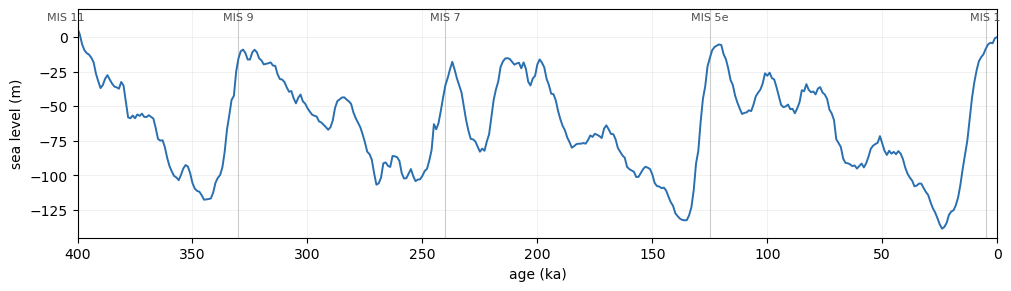

In [2]:
T.sea_level();

## The reference run (100 m, uplift 0.3 mm/yr)

The profile through time: each line is the strip every 50 kyr (darker = older),
the dashed line the initial foundation. The uplift lifts each highstand reef out
of the sea and the next highstand builds a new one lower down: the present-day
profile (black) is a staircase of flat reef tops (the terraces) with a crest at
their outer edge.

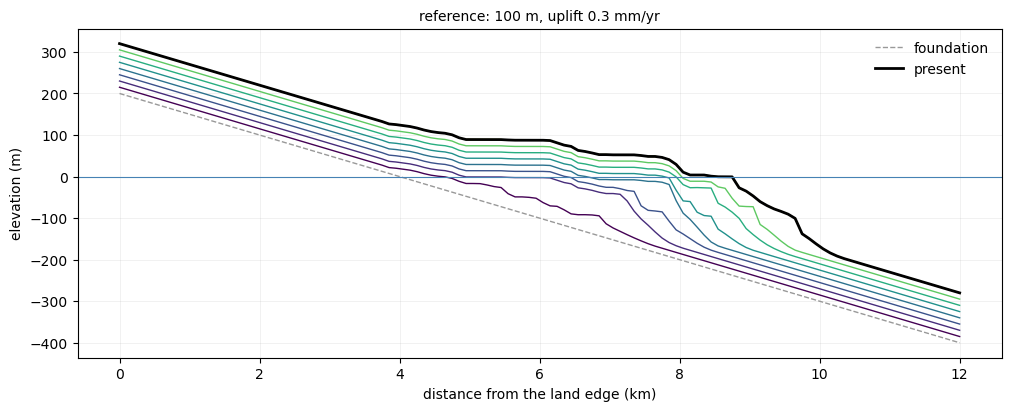

In [3]:
T.profile_evolution('sim_res100', title='reference: 100 m, uplift 0.3 mm/yr');

The stratigraphy along the strip: coloured by lithology (reef framework in pink,
loose carbonate sand light blue, carbonate mud dark blue) and by the age of the
layers (each terrace is younger than the one above it, landward).

Two factories produce the carbonate: the reef builders (framework in pink,
plus some loose sand and mud) at the shoreline, and a slower `platform`
factory of loose sand and mud down to 60 m, which fills the fore-reef slope
and the floor of the lagoons. The reef eroded by the waves is moved as
carbonate sand (`rubble: carb_sand`).

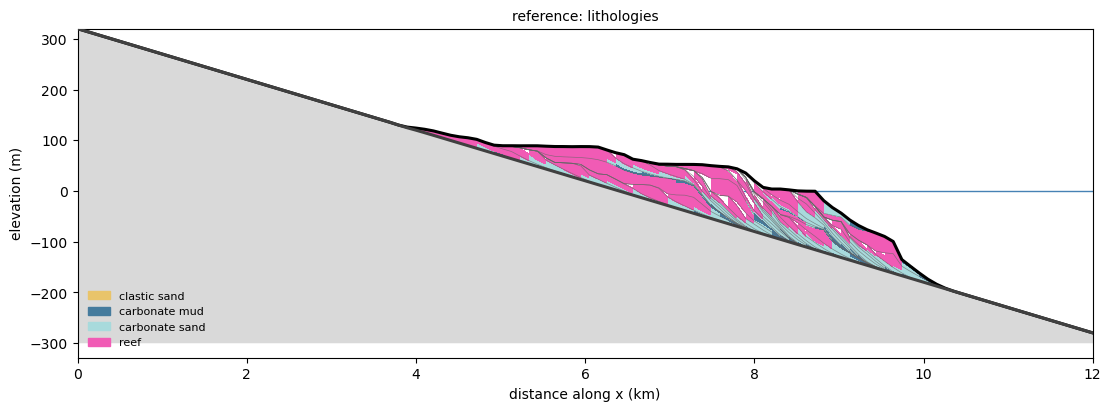

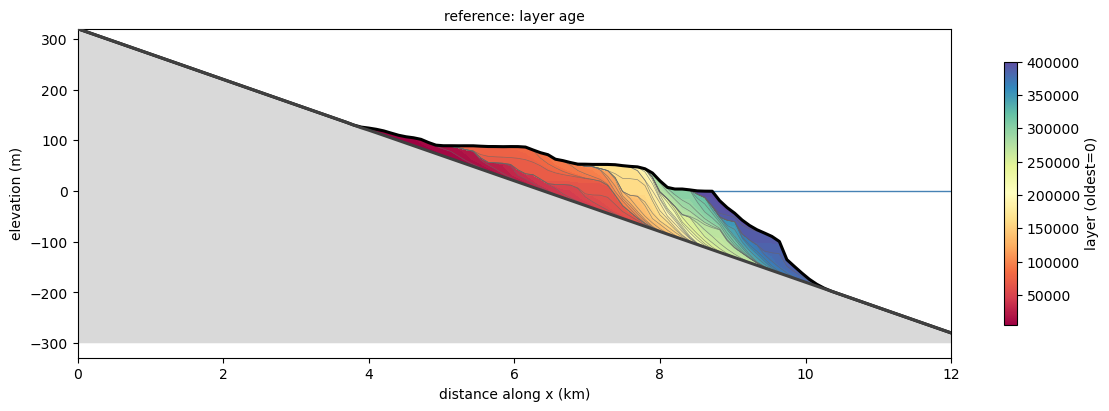

In [4]:
T.section('sim_res100', 'lithologies', title='reference: lithologies')
T.section('sim_res100', 'age', title='reference: layer age');

The carbonate budget: the reef framework and the loose carbonate produced per
step peak at the highstands; the coastal erosion works on the reefs exposed at
the shoreline.

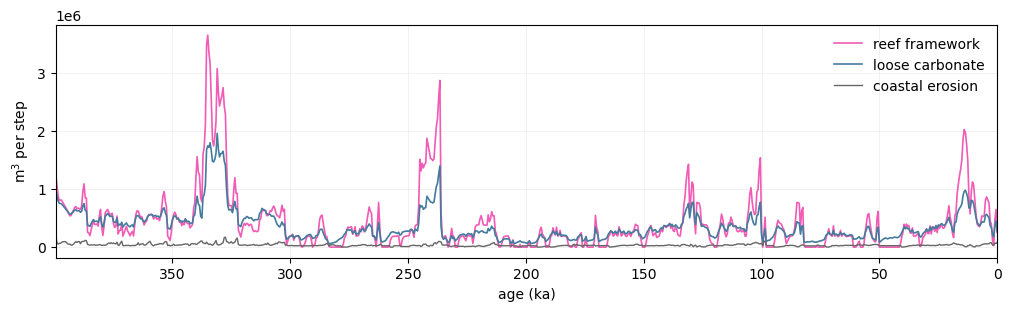

In [5]:
T.budget('summary_res100.jsonl');

## Resolution: 50, 100 and 200 m

The same configuration on three meshes. The terrace levels follow the sea-level
highstands and the uplift, and the three present-day profiles nearly coincide:
the carbonate growth is integrated per node and does not depend on the cell
size. The differences are the position of the steep reef fronts, which moves by
about one cell (they are drawn as sharp steps at 50 m, over two cells at
200 m).

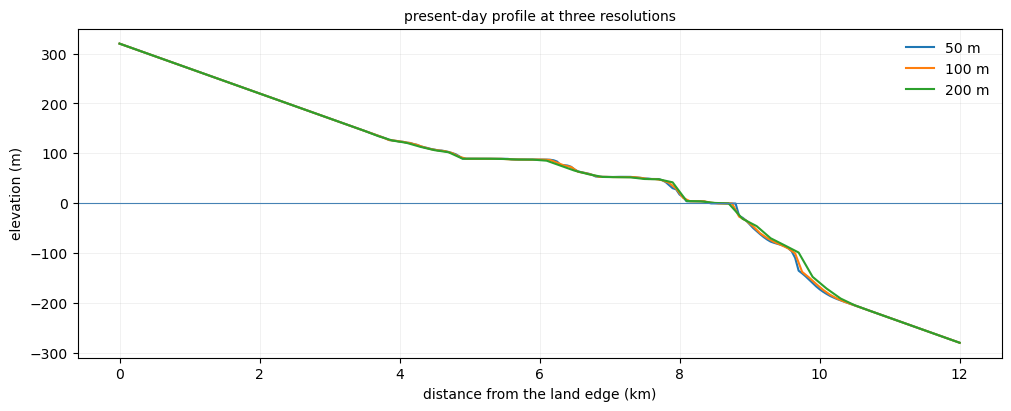

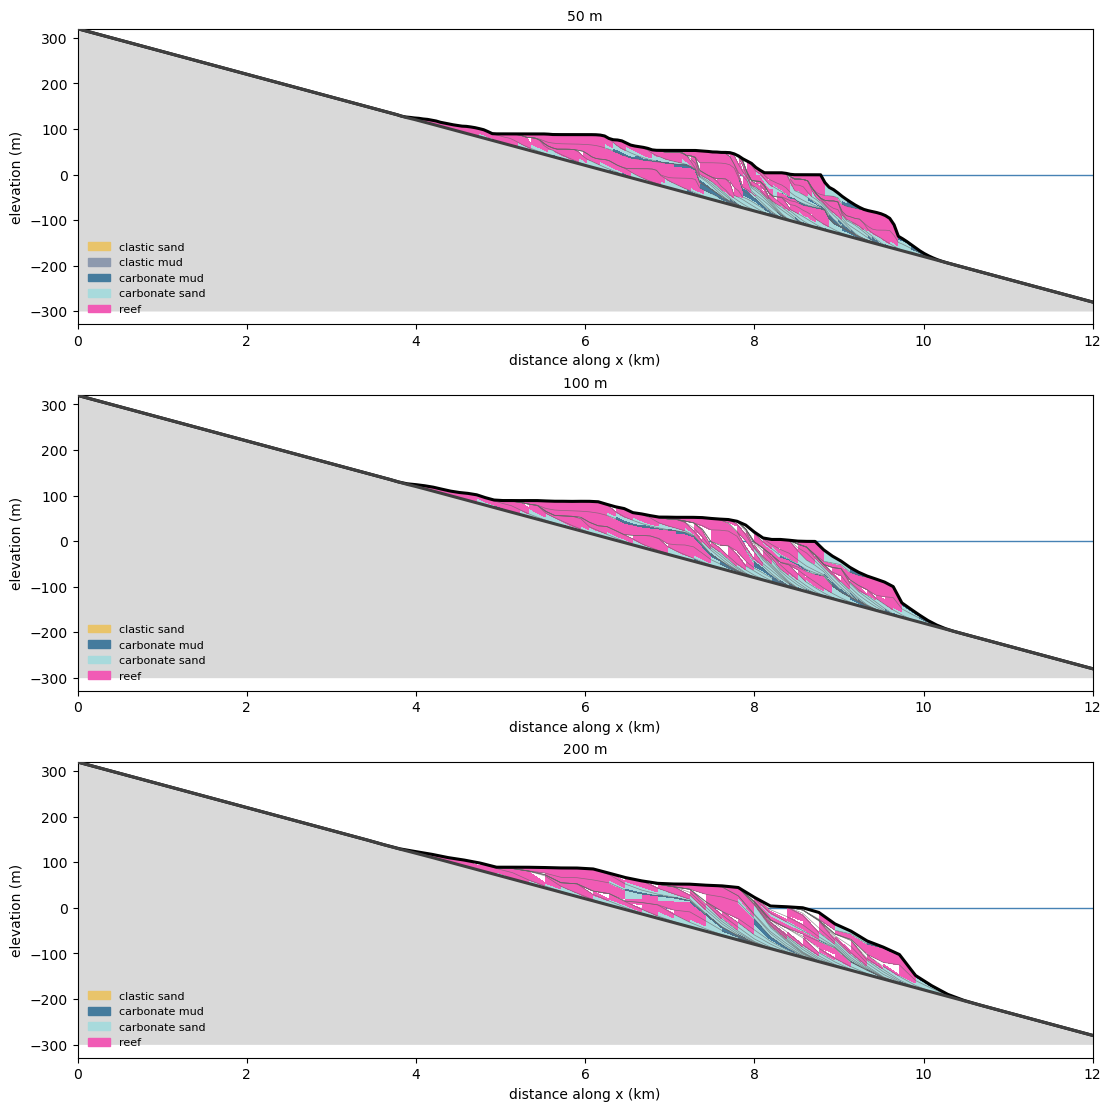

In [6]:
T.compare_profiles(['sim_res050', 'sim_res100', 'sim_res200'], ['50 m', '100 m', '200 m'],
                   title='present-day profile at three resolutions')
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
for a, (sim, res) in zip(ax, (('sim_res050', 50), ('sim_res100', 100), ('sim_res200', 200))):
    T.section(sim, 'lithologies', res=res, ax=a, title='%d m' % res)

## Vertical motion: uplift, stationary, subsidence

Pastier et al. (2019) find that the vertical motion of the coast controls the
architecture first. With uplift the highstand reefs are lifted and preserved as
a staircase; without vertical motion each highstand rebuilds a reef on the same
foundation (few terraces); with subsidence the reefs stack up and the older ones
drown below the present sea level.

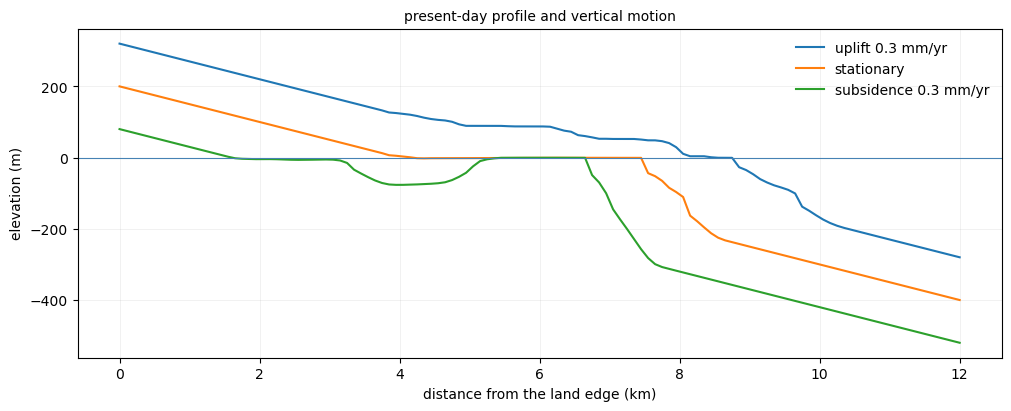

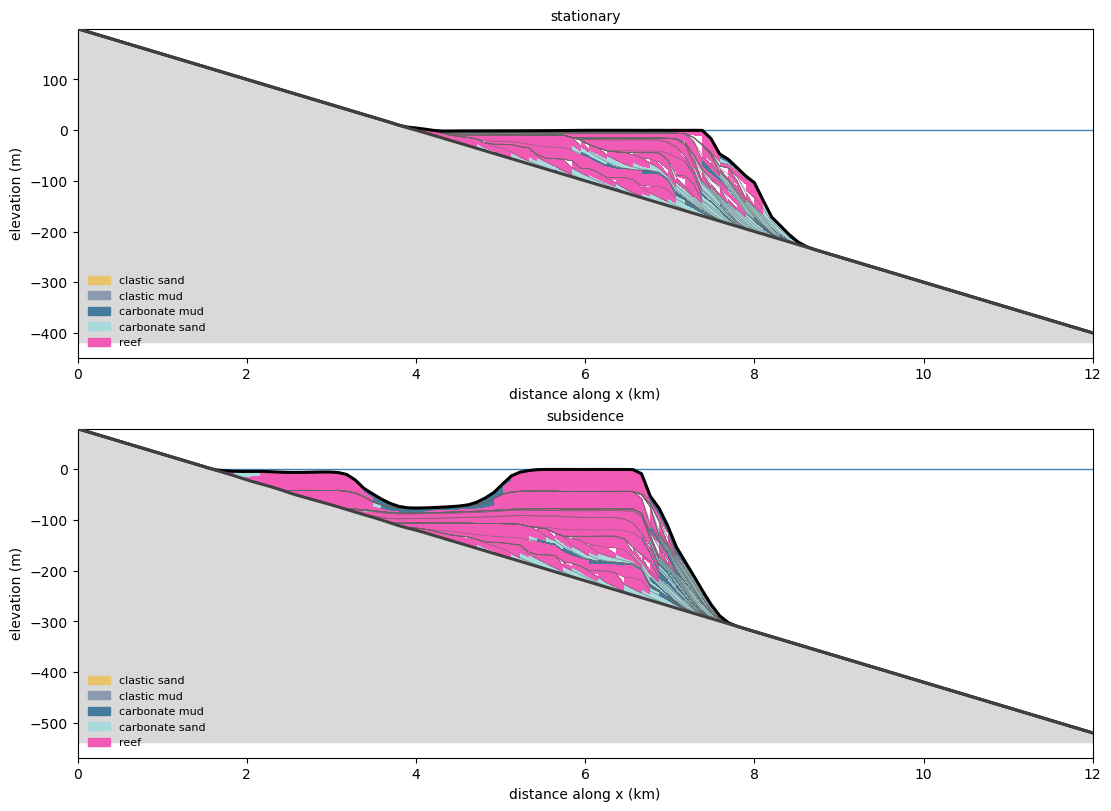

In [7]:
T.compare_profiles(['sim_res100', 'sim_stationary', 'sim_subsidence'],
                   ['uplift 0.3 mm/yr', 'stationary', 'subsidence 0.3 mm/yr'],
                   title='present-day profile and vertical motion')
fig, ax = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
T.section('sim_stationary', 'lithologies', ax=ax[0], title='stationary')
T.section('sim_subsidence', 'lithologies', ax=ax[1], title='subsidence');

## Options: factories alone, with waves, with coastal erosion (subsiding coast)

The options matter where the reef shelters water behind it, so they are compared
on the subsiding coast:

- *no waves* (`input-sub_reefonly.yml`): the factories grow wherever the light
  allows; the whole platform fills up to sea level (the lagoon floor is at
  -1 m).
- *+ waves* (`input-sub_waves.yml`): the `wave` control keeps the reef on the
  exposed edge and slows it in the sheltered water behind: a barrier reef with a
  lagoon 77 m deep, floored by platform sand and mud.
- *+ coastal erosion* (`input-subsidence.yml`): at 2 mm/yr the waves abrade the
  shallow seafloor and the reef crest a little, but on a sinking coast the reef
  moves away from the erosion faster than it is cut, and the profile hardly
  changes. Stronger erosion changes it (see the end of the next section).

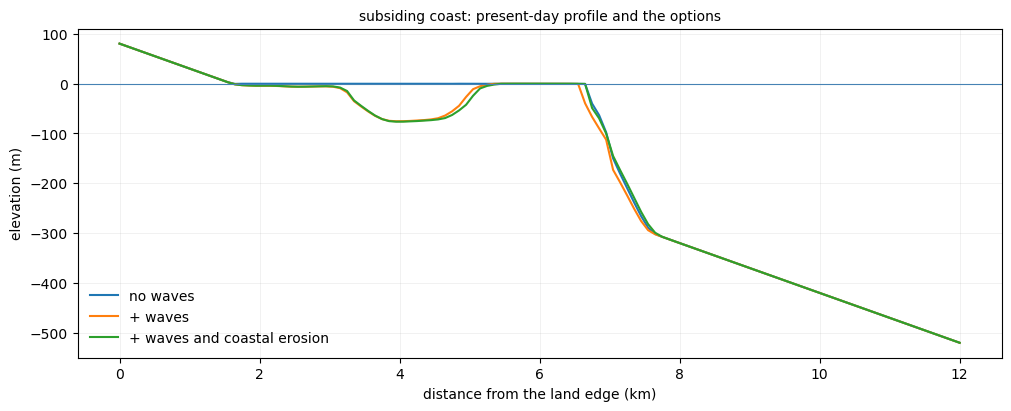

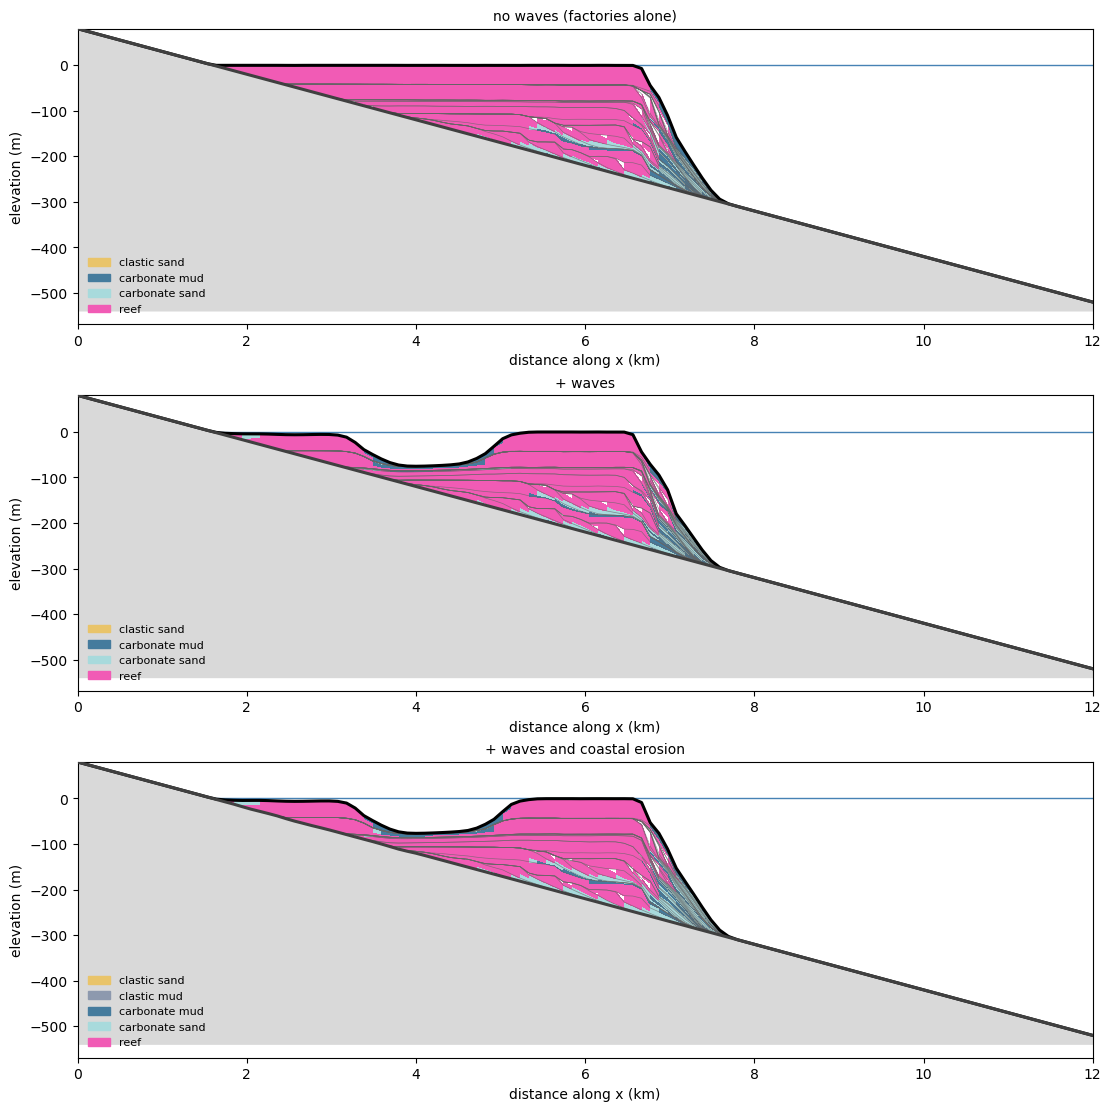

In [8]:
T.compare_profiles(['sim_sub_reefonly', 'sim_sub_waves', 'sim_subsidence'],
                   ['no waves', '+ waves', '+ waves and coastal erosion'],
                   title='subsiding coast: present-day profile and the options')
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
T.section('sim_sub_reefonly', 'lithologies', ax=ax[0], title='no waves (factories alone)')
T.section('sim_sub_waves', 'lithologies', ax=ax[1], title='+ waves')
T.section('sim_subsidence', 'lithologies', ax=ax[2], title='+ waves and coastal erosion');

## Coastal erosion strength (uplifting coast)

The reference erodes at most 2 mm/yr (at full wave energy, at sea level; ten
times less in reef framework). Five times stronger erosion (`input-erosion10.yml`,
closer to the erosional potential used by Pastier et al.) erodes 183 million m3
over the run instead of 28 million, cuts back the emerged reef crests and
widens the platform at sea level (8.6 to 9.1 km, against 8.4 to 8.8 km). The
eroded reef becomes carbonate sand that builds the fore-reef out (the -150 m
contour moves 200 m seaward), and the space opened at sea level is filled by
new reef: the run builds 22 % more framework than the reference.

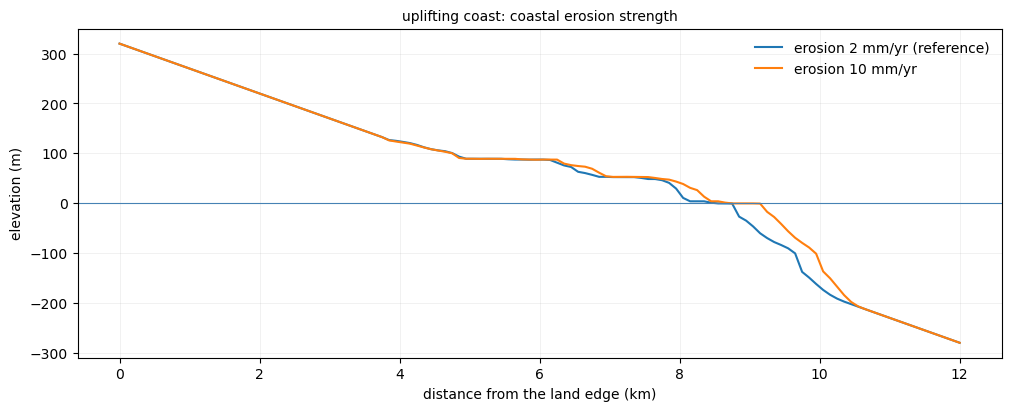

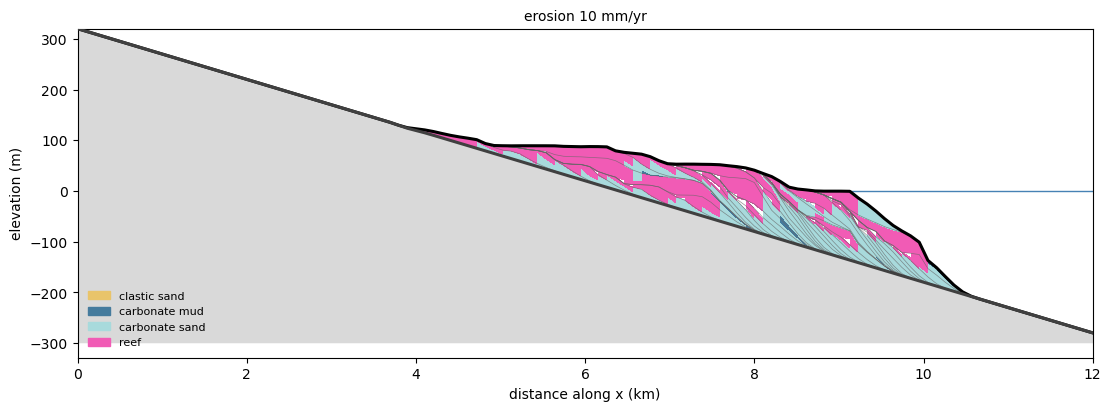

In [9]:
T.compare_profiles(['sim_res100', 'sim_erosion10'], ['erosion 2 mm/yr (reference)', 'erosion 10 mm/yr'],
                   title='uplifting coast: coastal erosion strength')
T.section('sim_erosion10', 'lithologies', title='erosion 10 mm/yr');

### Stronger erosion on the subsiding coast

At 2 mm/yr the erosion hardly shows on the subsiding coast: it removes 3 % of
the carbonate produced, the reef (eroded ten times slower than loose
sediment) grows back faster than it is cut, and no old reef stays above sea
level to be cut as a cliff. At 10 mm/yr (`input-sub_erosion10.yml`) it removes
17 %, and the eroded reef, moved as carbonate sand, changes the architecture:
a sand apron builds the fore-reef out (the -100 m contour moves from 7.1 to
7.6 km), the barrier reef steps seaward with it (its top from 5.2-6.7 km to
5.4-6.9 km), and the space cut at sea level is filled by new reef (19 % more
framework). The lagoon keeps its depth.

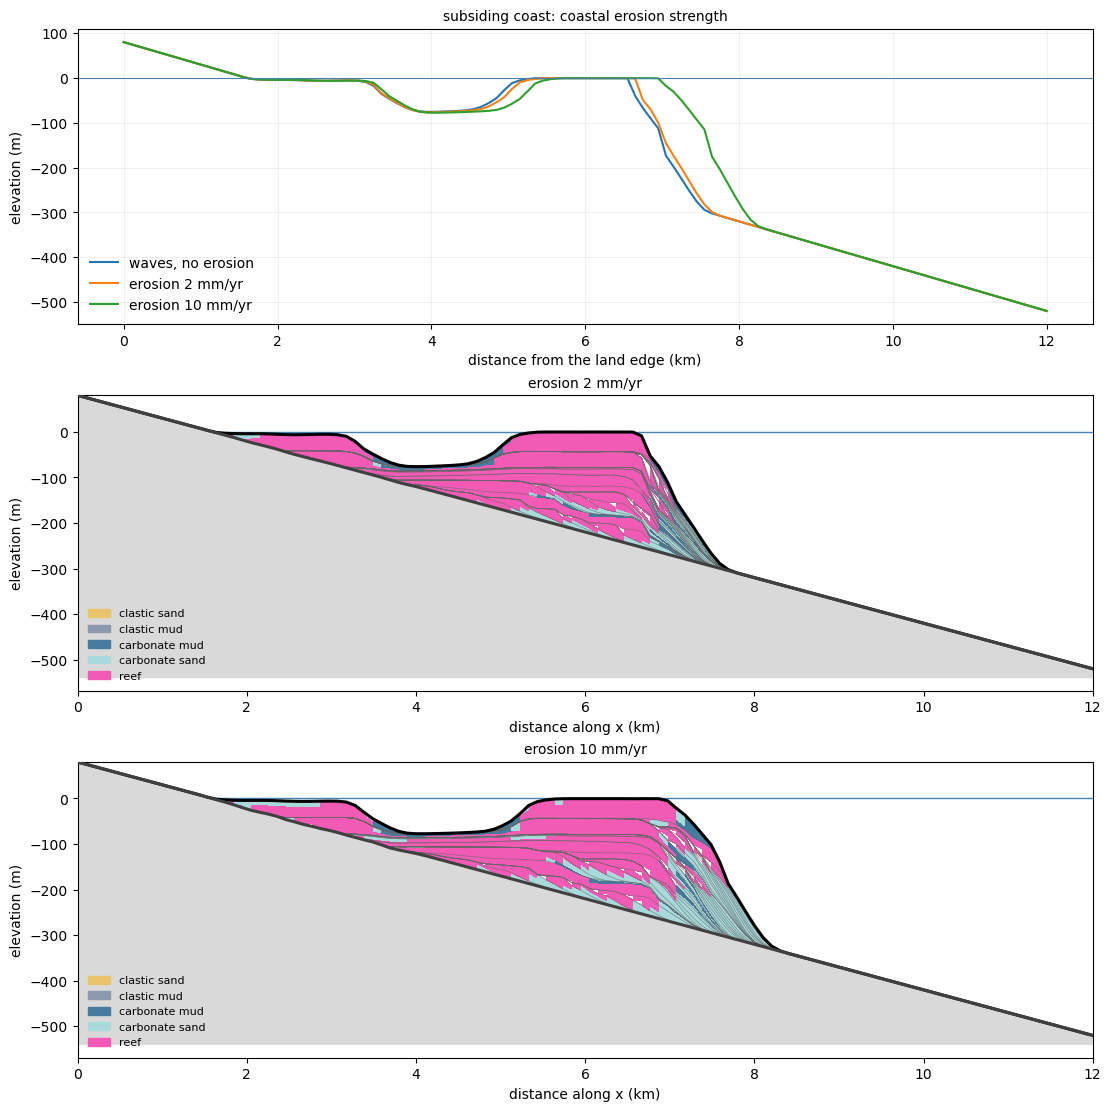

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
T.compare_profiles(['sim_sub_waves', 'sim_subsidence', 'sim_sub_erosion10'],
                   ['waves, no erosion', 'erosion 2 mm/yr', 'erosion 10 mm/yr'], ax=ax[0],
                   title='subsiding coast: coastal erosion strength')
T.section('sim_subsidence', 'lithologies', ax=ax[1], title='erosion 2 mm/yr')
T.section('sim_sub_erosion10', 'lithologies', ax=ax[2], title='erosion 10 mm/yr');

## A note on symmetry

The strip is uniform across its width, and on the uplifting coast the results
stay uniform (mirror differences below 2 m). On the stationary and subsiding
coasts the reef fronts become ragged across the strip, by up to a few tens of
metres. This is not a mesh or parallel artefact: the reef growth has an
unstable threshold (the give-up depth), so a cell just above it keeps up with
the sea and its neighbour just below drowns, and the round-off of the solvers
is enough to decide which. The same run on 1 and on 4 processors gives fronts
that differ in the same way. Use a strip wide enough to average them, or
compare the centre-line profiles, as here.